# Agendamento de bombas da ETA — Pyomo + HiGHS

Mesmo problema do notebook `ETA_agendamento_bombas_tarifa_aneel_sp.ipynb` (MILP de 24 horas: 6 bombas, 5 reservatórios, 12 setores, tarifa horossazonal da ANEEL), mas escrito em **Pyomo** e resolvido com **HiGHS**, solver de código aberto.

**Por que migrar:** a licença restrita do Gurobi (`pip install gurobipy`) limita o modelo a cerca de 2.000 variáveis e 2.000 restrições. O caso de 1 dia (1.080 variáveis) cabe, mas horizontes maiores (2 dias ou mais) não. Com HiGHS não há esse limite.

**Como usar:** edite os parâmetros da próxima célula e execute o notebook de cima para baixo. Para abrir a tela em Tkinter, veja a última seção.

Requisitos: `pip install pyomo highspy pandas numpy matplotlib` (e o CSV `dados/tarifas-homologadas-distribuidoras-energia-eletrica.csv`, o mesmo do outro notebook).

## 1. Parâmetros do cenário

- `DEMANDA_DIARIA_M3`: demanda de **água** do dia em m³ (o consumo de energia em kWh é o **resultado** da otimização). `None` usa a demanda do cenário original, 12.787,2 m³/dia.
- `DIAS`: com mais de 1 dia a curva de demanda é repetida (o modelo cresce e o solver demora mais).
- `MIP_GAP`: critério de parada do solver para a diferença entre a solução encontrada e o limite inferior. Não é uma tolerância para trocar custo por redução de vazão.

In [1]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

warnings.filterwarnings("ignore")

def br(v, nd=0):
    """Formata número no padrão brasileiro (12.787,2)."""
    return f"{v:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

# ===== Parâmetros do cenário (edite aqui) =====
DISTRIBUIDORA = "ELETROPAULO"   # ELETROPAULO, EDP SP, CPFL-PAULISTA, CPFL-PIRATINING, CPFL Santa Cruz, ELEKTRO
MODALIDADE = "Verde"            # Verde ou Azul
SUBGRUPO = "A4"
DATA_REF = "2026-10-06"         # data usada para escolher a tarifa vigente
DEMANDA_DIARIA_M3 = None        # None = cenário original (12.787,2 m³/dia); ou ex.: 13500
DIAS = 1                        # horizonte em dias
MIP_GAP = 0.01                  # 1 %
LIMITE_S = 120                  # limite de tempo do solver (segundos)

## 2. Dados da ETA

Os mesmos do notebook original: potência e vazão máxima das bombas, volumes dos reservatórios, ligações bomba→reservatório e reservatório→setor, e a curva horária de demanda de verão.

In [2]:
HORAS_PONTA = (17, 18, 19)
BOMBAS = list(range(1, 7))
RESERVATORIOS = list(range(1, 6))
SETORES = list(range(1, 13))
ARCOS_PR = [(1,1),(2,1),(2,2),(2,3),(3,2),(4,3),(4,4),(5,5),(6,4),(6,5)]
ARCOS_RS = [(1,1),(1,2),(1,3),(2,2),(2,4),(2,5),(3,4),(3,6),(3,7),(4,4),(4,8),(4,9),(4,10),(4,12),
            (5,7),(5,10),(5,11),(5,12)]
PARAM_BOMBAS = {1:(60,0,150), 2:(120,0,280), 3:(70,0,150), 4:(80,0,180), 5:(50,0,120), 6:(70,0,150)}  # kW, Qmin, Qmax (m³/h)
Q_ETA_MAX = 600                                                                                       # m³/h
PARAM_RES = {1:(135,900,270), 2:(90,600,180), 3:(90,600,180), 4:(90,600,180), 5:(45,300,90)}          # Vmin, Vmax, Vini (m³)
BASE_DEMANDA = {1:20,2:30,3:25,4:40,5:25,6:20,7:35,8:30,9:20,10:45,11:25,12:18}
CURVA_VERAO = [0.8,0.5,0.3,0.4,0.6,1.0, 1.8,2.0,1.9,1.7,1.5,1.5, 1.4,1.5,1.6,1.7,1.8,2.9, 3.4,3.0,2.6,2.0,1.5,1.0]
DEMANDA_DIARIA_BASE = round(sum(BASE_DEMANDA.values()) * sum(CURVA_VERAO), 1)   # 12.787,2 m³/dia

def demanda(dias=1, fator=1.0):
    """Demanda horária por setor (m³/h). `fator` escala a curva; dias > 1 repete a curva."""
    return {(d, t): round(BASE_DEMANDA[d] * CURVA_VERAO[t % 24] * fator, 4) for d in SETORES for t in range(24 * dias)}

FATOR = (DEMANDA_DIARIA_M3 or DEMANDA_DIARIA_BASE) / DEMANDA_DIARIA_BASE
print(f"Demanda de água: {br(DEMANDA_DIARIA_BASE * FATOR, 1)} m³/dia | capacidade teórica da ETA: {br(Q_ETA_MAX*24)} m³/dia")

Demanda de água: 12.787,2 m³/dia | capacidade teórica da ETA: 14.400 m³/dia


## 3. Tarifas da ANEEL

Mesma regra do notebook original: R$/kWh = (TUSD + TE em R$/MWh) ÷ 1.000, sem tributos nem bandeiras. A função `data_efetiva` trata datas em que o CSV ainda não tem a tarifa vigente (por exemplo, reajuste ainda não publicado): usa a vigência mais recente e avisa.

In [3]:
NOME_CSV = "tarifas-homologadas-distribuidoras-energia-eletrica.csv"

def achar_csv():
    for base in [Path.cwd(), *Path.cwd().parents]:
        c = base / "dados" / NOME_CSV
        if c.is_file():
            return c
    raise FileNotFoundError(f"dados/{NOME_CSV} não encontrado a partir de {Path.cwd()}")

def carregar_csv(csv):
    df = pd.read_csv(csv, sep=";", dtype=str)
    for c in ["DatInicioVigencia", "DatFimVigencia"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in ["VlrTUSD", "VlrTE"]:
        df[c] = pd.to_numeric(df[c].str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
    return df

def _base(df, dist, mod, sub):
    return df[(df.SigAgente == dist) & (df.DscBaseTarifaria == "Tarifa de Aplicação") & (df.DscModalidadeTarifaria == mod)
              & (df.DscSubGrupo == sub) & (df.DscClasse == "Não se aplica") & (df.DscSubClasse == "Não se aplica")
              & (df.DscDetalhe == "Não se aplica") & (df.SigAgenteAcessante == "Não se aplica")]

def data_efetiva(df, dist, mod, sub, data_ref):
    ref = pd.Timestamp(data_ref)
    f = _base(df, dist, mod, sub)
    ant = f[f.DatInicioVigencia <= ref]
    if ant.empty:
        raise ValueError(f"Sem tarifa de {dist}/{mod}/{sub} até {ref.date()}")
    if (ant.DatFimVigencia >= ref).any():
        return ref, None
    u = ant.sort_values(["DatInicioVigencia", "DatFimVigencia"]).iloc[-1]
    return pd.Timestamp(u.DatInicioVigencia), (f"CSV sem tarifa vigente em {ref:%d/%m/%Y} para {dist}; usada a vigência "
                                               f"{u.DatInicioVigencia:%d/%m/%Y} a {u.DatFimVigencia:%d/%m/%Y}.")

def tarifa_aneel(df, dist, mod, sub, data):
    """(fora_ponta, ponta) em R$/kWh."""
    f = _base(df, dist, mod, sub)
    d = pd.Timestamp(data)
    f = f[(f.DatInicioVigencia <= d) & (f.DatFimVigencia >= d) & (f.DscUnidadeTerciaria == "MWh")
          & (f.NomPostoTarifario.isin(["Ponta", "Fora ponta"]))]
    v = ((f.VlrTUSD.fillna(0) + f.VlrTE.fillna(0)) / 1000).groupby(f.NomPostoTarifario).first()
    return float(v["Fora ponta"]), float(v["Ponta"])

def tarifa_demanda_kw(df, dist, mod, sub, data):
    """Tarifa de demanda (TUSD, R$/kW). Azul: ponta e fora ponta; Verde: única."""
    f = _base(df, dist, mod, sub)
    d = pd.Timestamp(data)
    f = f[(f.DatInicioVigencia <= d) & (f.DatFimVigencia >= d) & (f.DscUnidadeTerciaria == "kW")]
    p = f.groupby("NomPostoTarifario")["VlrTUSD"].first()
    return ({"ponta": float(p["Ponta"]), "fora_ponta": float(p["Fora ponta"])} if mod == "Azul"
            else {"unica": float(p["Não se aplica"])})

CSV = achar_csv()
ANEEL = carregar_csv(CSV)
data_uso, aviso = data_efetiva(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, DATA_REF)
tarifa_fora_ponta, tarifa_ponta = tarifa_aneel(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, data_uso)
print(f"{DISTRIBUIDORA} | {MODALIDADE} | {SUBGRUPO} | tarifa consultada em {data_uso:%d/%m/%Y}")
print(f"  Fora ponta: R$ {br(tarifa_fora_ponta, 4)}/kWh")
print(f"  Ponta:      R$ {br(tarifa_ponta, 4)}/kWh  ({br(tarifa_ponta / tarifa_fora_ponta, 2)}x o fora ponta)")
if aviso:
    print("  AVISO:", aviso)

ELETROPAULO | Verde | A4 | tarifa consultada em 06/10/2026
  Fora ponta: R$ 0,4525/kWh
  Ponta:      R$ 1,4048/kWh  (3,10x o fora ponta)


## 4. Modelo em Pyomo

Estrutura idêntica à do Gurobi:

- **Variáveis:** `x[p,t]` (bomba ligada, binária), `q[p,t]` (vazão da bomba), `fpr` (vazão bomba→reservatório), `frs` (vazão reservatório→setor), `V[r,t]` (volume).
- **Objetivo:** minimizar o custo de energia mais uma estimativa diária da demanda de potência. Na modalidade Verde usa-se o pico do horizonte; na Azul, os picos de ponta e fora ponta. A parcela mensal de demanda é rateada por `DIAS/30`.
- **Restrições:** vazão de cada bomba entre 0 e $Q_{max}$ quando ligada; ETA limitada a 600 m³/h; demanda de cada setor atendida exatamente; balanço de volume nos reservatórios; volume entre mínimo e máximo; volume final maior ou igual ao inicial.

In [4]:
def construir(c_fora, c_ponta, dias=1, fator_demanda=1.0, horas_ponta=HORAS_PONTA, tarifa_demanda=None):
    T = 24 * dias
    D = demanda(dias, fator_demanda)
    C = {t: (c_ponta if (t % 24) in horas_ponta else c_fora) for t in range(T)}
    m = pyo.ConcreteModel("ETA_bombas")
    m.H = pyo.RangeSet(0, T - 1)
    m.P = pyo.Set(initialize=BOMBAS); m.R = pyo.Set(initialize=RESERVATORIOS); m.S = pyo.Set(initialize=SETORES)
    m.APR = pyo.Set(initialize=ARCOS_PR, dimen=2); m.ARS = pyo.Set(initialize=ARCOS_RS, dimen=2)

    m.x = pyo.Var(m.P, m.H, within=pyo.Binary)
    m.q = pyo.Var(m.P, m.H, within=pyo.NonNegativeReals)
    m.fpr = pyo.Var(m.APR, m.H, within=pyo.NonNegativeReals)
    m.frs = pyo.Var(m.ARS, m.H, within=pyo.NonNegativeReals)
    m.V = pyo.Var(m.R, m.H, within=pyo.NonNegativeReals)
    for r in RESERVATORIOS:                      # limites de volume como bounds das variáveis
        for t in range(T):
            m.V[r, t].setlb(PARAM_RES[r][0]); m.V[r, t].setub(PARAM_RES[r][1])

    m.kw_total = pyo.Expression(m.H, rule=lambda m, t: sum(PARAM_BOMBAS[p][0] * m.x[p, t] for p in m.P))
    m.custo_energia = pyo.Expression(expr=sum(C[t] * m.kw_total[t] for t in m.H))
    custo_demanda_expr = 0
    if tarifa_demanda is not None:
        if "unica" in tarifa_demanda:
            m.kw_pico = pyo.Var(within=pyo.NonNegativeReals)
            m.limite_pico = pyo.Constraint(m.H, rule=lambda m, t: m.kw_pico >= m.kw_total[t])
            custo_demanda_expr = (dias / 30) * tarifa_demanda["unica"] * m.kw_pico
        elif {"ponta", "fora_ponta"} <= tarifa_demanda.keys():
            horas_ponta = set(horas_ponta)
            m.kw_pico_ponta = pyo.Var(within=pyo.NonNegativeReals)
            m.kw_pico_fora = pyo.Var(within=pyo.NonNegativeReals)
            m.limite_pico_ponta = pyo.Constraint(m.H, rule=lambda m, t: m.kw_pico_ponta >= m.kw_total[t] if t % 24 in horas_ponta else pyo.Constraint.Skip)
            m.limite_pico_fora = pyo.Constraint(m.H, rule=lambda m, t: m.kw_pico_fora >= m.kw_total[t] if t % 24 not in horas_ponta else pyo.Constraint.Skip)
            custo_demanda_expr = (dias / 30) * (tarifa_demanda["ponta"] * m.kw_pico_ponta + tarifa_demanda["fora_ponta"] * m.kw_pico_fora)
        else:
            raise ValueError("Tarifas de demanda inválidas: informe 'unica' ou 'ponta' e 'fora_ponta'.")
    m.custo_demanda = pyo.Expression(expr=custo_demanda_expr)
    m.obj = pyo.Objective(expr=m.custo_energia + m.custo_demanda, sense=pyo.minimize)

    m.qmin = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] >= PARAM_BOMBAS[p][1] * m.x[p, t])
    m.qmax = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] <= PARAM_BOMBAS[p][2] * m.x[p, t])
    m.qsoma = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] == sum(m.fpr[a, r, t] for (a, r) in ARCOS_PR if a == p))
    m.eta = pyo.Constraint(m.H, rule=lambda m, t: sum(m.q[p, t] for p in m.P) <= Q_ETA_MAX)
    m.dem = pyo.Constraint(m.S, m.H, rule=lambda m, s, t: sum(m.frs[r, d, t] for (r, d) in ARCOS_RS if d == s) == D[s, t])

    def balanco(m, r, t):
        entra = sum(m.fpr[p, rr, t] for (p, rr) in ARCOS_PR if rr == r)
        sai = sum(m.frs[rr, s, t] for (rr, s) in ARCOS_RS if rr == r)
        return m.V[r, t] == (PARAM_RES[r][2] if t == 0 else m.V[r, t - 1]) + entra - sai
    m.bal = pyo.Constraint(m.R, m.H, rule=balanco)
    m.rec = pyo.Constraint(m.R, rule=lambda m, r: m.V[r, T - 1] >= PARAM_RES[r][2])
    return m

def resolver(m, gap=MIP_GAP, limite=LIMITE_S, log=False):
    """Resolve com HiGHS. Retorna (segundos, custo, gap final, condição de término)."""
    s = pyo.SolverFactory("appsi_highs")
    s.highs_options = {"mip_rel_gap": gap, "time_limit": float(limite), "output_flag": log, "mip_heuristic_effort": 0.3}
    t0 = time.time()
    res = s.solve(m)
    ub, lb = res.problem.upper_bound, res.problem.lower_bound
    return time.time() - t0, ub, (ub - lb) / ub, str(res.solver.termination_condition)

## 5. Otimização

In [5]:
tarifa_demanda = tarifa_demanda_kw(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, data_uso)
modelo = construir(tarifa_fora_ponta, tarifa_ponta, dias=DIAS, fator_demanda=FATOR,
                   tarifa_demanda=tarifa_demanda)
n_var = sum(1 for _ in modelo.component_data_objects(pyo.Var))
n_bin = sum(1 for _ in modelo.x.values())
n_res = sum(1 for _ in modelo.component_data_objects(pyo.Constraint, active=True))
print(f"Modelo: {n_var} variáveis ({n_bin} binárias) e {n_res} restrições "
      f"(o Gurobi restrito aceita no máximo ~2.000 de cada)")

tempo, custo, gap_final, termino = resolver(modelo)
print(f"\nSolver HiGHS: {termino} | {br(tempo, 1)} s | gap final {br(gap_final*100, 2)}%")
print(f"Custo de energia: R$ {br(pyo.value(modelo.custo_energia), 2)}")
print(f"Demanda rateada: R$ {br(pyo.value(modelo.custo_demanda), 2)}")
print(f"Custo total do plano: R$ {br(custo, 2)}")

Modelo: 1081 variáveis (144 binárias) e 893 restrições (o Gurobi restrito aceita no máximo ~2.000 de cada)

Solver HiGHS: optimal | 15,9 s | gap final 0,82%
Custo de energia: R$ 2.889,20
Demanda rateada: R$ 165,01
Custo total do plano: R$ 3.054,22


## 6. Resultados e horários de acionamento das bombas

In [6]:
T = 24 * DIAS
D = demanda(DIAS, FATOR)
linhas = []
for t in range(T):
    lig = [p for p in BOMBAS if pyo.value(modelo.x[p, t]) > 0.5]
    ponta = (t % 24) in HORAS_PONTA
    linhas.append({"Hora": f"{t:02d}:00-{t+1:02d}:00", "Faixa": "PONTA" if ponta else "fora ponta",
                   "Tarifa (R$/kWh)": tarifa_ponta if ponta else tarifa_fora_ponta,
                   "Bombas ligadas": ", ".join(map(str, lig)) or "-",
                   "Vazão (m³/h)": round(sum(pyo.value(modelo.q[p, t]) for p in BOMBAS)),
                   "Demanda (m³/h)": round(sum(D[s, t] for s in SETORES)),
                   "Potência (kW)": sum(PARAM_BOMBAS[p][0] for p in lig), "_lig": lig, "_ponta": ponta})
plano = pd.DataFrame(linhas)

kwh = plano["Potência (kW)"].sum()
kwh_ponta = plano.loc[plano._ponta, "Potência (kW)"].sum()
print(f"Energia: {br(kwh)} kWh/dia ({br(kwh_ponta)} kWh na ponta = {br(kwh_ponta/kwh*100, 1)}%)")
print(f"Potência média: {br(kwh/T)} kW | máxima: {plano['Potência (kW)'].max()} kW | custo médio de energia: R$ {br(pyo.value(modelo.custo_energia)/kwh, 3)}/kWh")

def intervalos(horas):
    out, ini, ant = [], None, None
    for h in sorted(horas):
        if ini is None: ini = ant = h
        elif h == ant + 1: ant = h
        else: out.append((ini, ant + 1)); ini = ant = h
    if ini is not None: out.append((ini, ant + 1))
    return ", ".join(f"{a:02d}:00-{b:02d}:00" for a, b in out) or "-"

print("\nQuando ligar cada bomba:")
for p in BOMBAS:
    hs = [t for t in range(T) if p in plano._lig[t]]
    print(f"  Bomba {p} ({PARAM_BOMBAS[p][0]:>3} kW): {intervalos(hs)}   [{len(hs)} h]")

plano.drop(columns=["_lig", "_ponta"]).style.format({"Tarifa (R$/kWh)": "{:.4f}"}).apply(
    lambda s: ["background-color: #FFEBEE" if v == "PONTA" else "" for v in s], subset=["Faixa"])

Energia: 5.480 kWh/dia (430 kWh na ponta = 7,8%)
Potência média: 228 kW | máxima: 260 kW | custo médio de energia: R$ 0,527/kWh

Quando ligar cada bomba:
  Bomba 1 ( 60 kW): 00:00-06:00, 07:00-10:00, 11:00-13:00, 20:00-24:00   [15 h]
  Bomba 2 (120 kW): 00:00-02:00, 03:00-04:00, 05:00-09:00, 10:00-17:00, 18:00-19:00, 21:00-22:00, 23:00-24:00   [17 h]
  Bomba 3 ( 70 kW): -   [0 h]
  Bomba 4 ( 80 kW): 02:00-05:00, 06:00-07:00, 09:00-11:00, 13:00-19:00, 20:00-24:00   [16 h]
  Bomba 5 ( 50 kW): 00:00-03:00, 04:00-21:00, 22:00-23:00   [21 h]
  Bomba 6 ( 70 kW): 09:00-10:00, 20:00-21:00, 22:00-23:00   [3 h]


,Hora,Faixa,Tarifa (R$/kWh),Bombas ligadas,Vazão (m³/h),Demanda (m³/h),Potência (kW)
0,00:00-01:00,fora ponta,0.4525,"1, 2, 5",507,266,230
1,01:00-02:00,fora ponta,0.4525,"1, 2, 5",550,166,230
2,02:00-03:00,fora ponta,0.4525,"1, 4, 5",450,100,190
3,03:00-04:00,fora ponta,0.4525,"1, 2, 4",600,133,260
4,04:00-05:00,fora ponta,0.4525,"1, 4, 5",450,200,190
5,05:00-06:00,fora ponta,0.4525,"1, 2, 5",550,333,230
6,06:00-07:00,fora ponta,0.4525,"2, 4, 5",580,599,250
7,07:00-08:00,fora ponta,0.4525,"1, 2, 5",550,666,230
8,08:00-09:00,fora ponta,0.4525,"1, 2, 5",550,633,230
9,09:00-10:00,fora ponta,0.4525,"1, 4, 5, 6",600,566,260


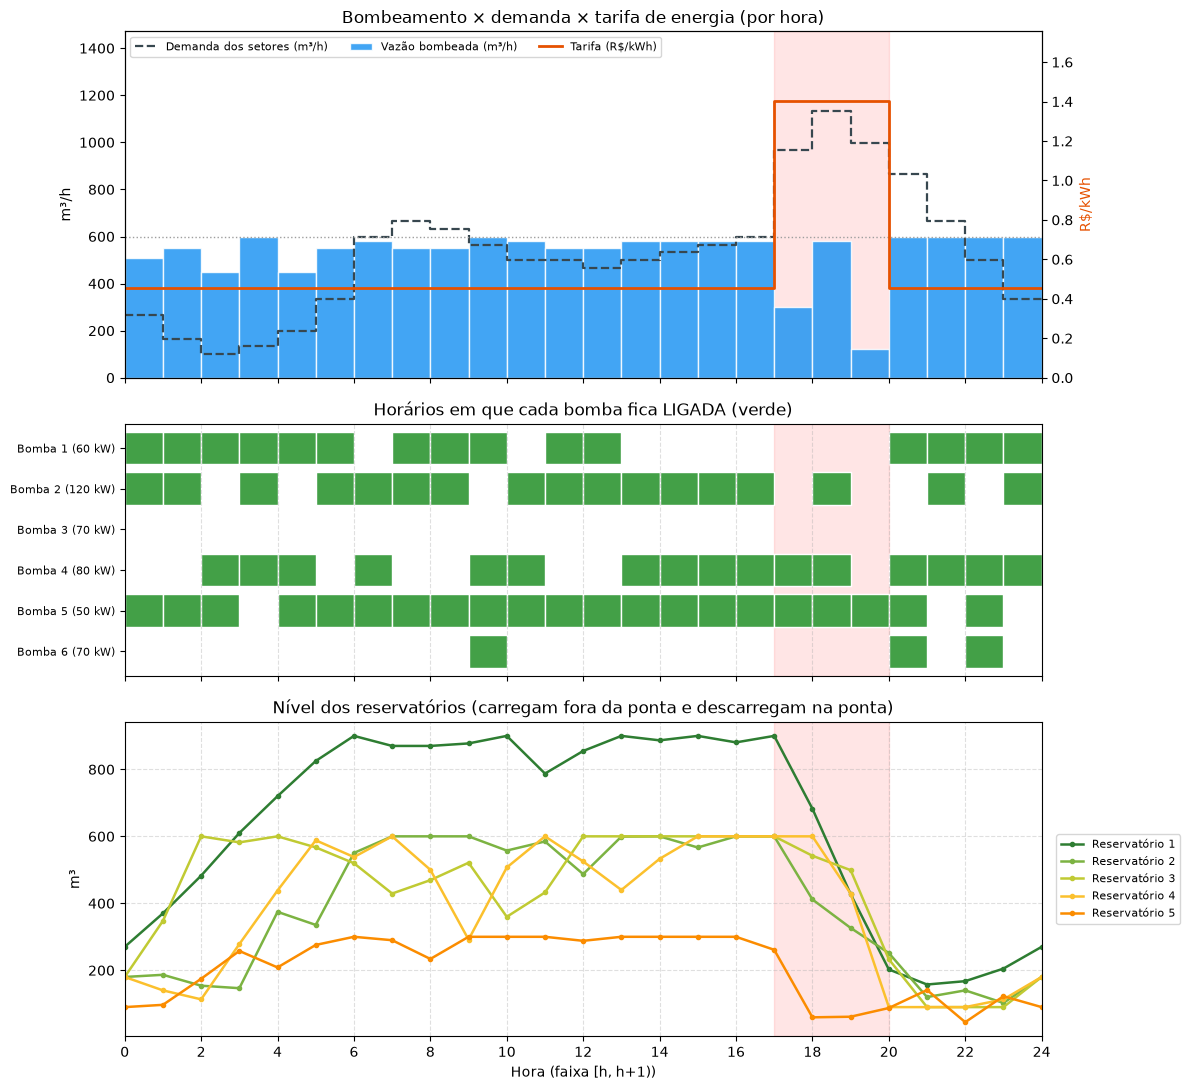

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.6, 2.0]})
x = np.arange(T)

ax1.bar(x, plano["Vazão (m³/h)"], width=1, align="edge", color="#2196F3", alpha=0.85, edgecolor="white", label="Vazão bombeada (m³/h)")
dem = plano["Demanda (m³/h)"].to_numpy()
ax1.step(np.append(x, T), np.append(dem, dem[-1]), where="post", color="#37474F", ls="--", lw=1.6, label="Demanda dos setores (m³/h)")
ax1.axhline(Q_ETA_MAX, color="#9E9E9E", ls=":", lw=1)
ax1.set_ylim(0, max(dem.max(), Q_ETA_MAX) * 1.3); ax1.set_ylabel("m³/h")
ax1.set_title("Bombeamento × demanda × tarifa de energia (por hora)")
tw = ax1.twinx(); tar = plano["Tarifa (R$/kWh)"].to_numpy()
tw.step(np.append(x, T), np.append(tar, tar[-1]), where="post", color="#E65100", lw=2, label="Tarifa (R$/kWh)")
tw.set_ylabel("R$/kWh", color="#E65100"); tw.set_ylim(0, tar.max() * 1.25)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = tw.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, ncol=3)

for p in BOMBAS:
    on = [(t, 1) for t in range(T) if p in plano._lig[t]]
    if on: ax2.broken_barh(on, (p - 0.4, 0.8), facecolors="#43A047", edgecolor="white")
ax2.set_ylim(6.6, 0.4); ax2.set_yticks(BOMBAS)
ax2.set_yticklabels([f"Bomba {p} ({PARAM_BOMBAS[p][0]} kW)" for p in BOMBAS], fontsize=8)
ax2.set_title("Horários em que cada bomba fica LIGADA (verde)"); ax2.grid(True, axis="x", ls="--", alpha=0.4)

cores = ["#2E7D32", "#7CB342", "#C0CA33", "#FBC02D", "#FB8C00"]
for i, r in enumerate(RESERVATORIOS):
    vol = [PARAM_RES[r][2]] + [pyo.value(modelo.V[r, t]) for t in range(T)]
    ax3.plot(range(T + 1), vol, marker="o", ms=3, lw=1.8, color=cores[i], label=f"Reservatório {r}")
ax3.set_ylabel("m³"); ax3.set_xlabel("Hora (faixa [h, h+1))")
ax3.set_title("Nível dos reservatórios (carregam fora da ponta e descarregam na ponta)")
ax3.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8); ax3.grid(True, ls="--", alpha=0.4)

for ax in (ax1, ax2, ax3):
    for d in range(DIAS):
        ax.axvspan(24 * d + min(HORAS_PONTA), 24 * d + max(HORAS_PONTA) + 1, color="red", alpha=0.10, zorder=0)
ax1.set_xlim(0, T); ax3.set_xticks(range(0, T + 1, 2))
plt.tight_layout(); plt.show()

## 7. Qual a demanda máxima que o modelo atende?

A capacidade teórica da ETA é 600 m³/h × 24 h = 14.400 m³/dia, mas isso só valeria se a demanda fosse constante. Como a curva de verão tem picos acima de 600 m³/h e os reservatórios guardam pouco, o máximo real é menor.

Como `Q_min = 0`, deixar todas as bombas disponíveis não restringe a viabilidade, então basta resolver um **LP** que maximiza o fator que multiplica a demanda.

In [8]:
def demanda_maxima_viavel():
    base = demanda(1, 1.0); T1 = 24
    m = pyo.ConcreteModel()
    m.f = pyo.Var(bounds=(0, 5))
    m.q = pyo.Var(BOMBAS, range(T1), bounds=(0, None))
    m.fpr = pyo.Var(ARCOS_PR, range(T1), bounds=(0, None))
    m.frs = pyo.Var(ARCOS_RS, range(T1), bounds=(0, None))
    m.V = pyo.Var(RESERVATORIOS, range(T1))
    for r in RESERVATORIOS:
        for t in range(T1):
            m.V[r, t].setlb(PARAM_RES[r][0]); m.V[r, t].setub(PARAM_RES[r][1])
    m.obj = pyo.Objective(expr=m.f, sense=pyo.maximize)
    m.c = pyo.ConstraintList()
    for p in BOMBAS:
        for t in range(T1):
            m.c.add(m.q[p, t] <= PARAM_BOMBAS[p][2])
            m.c.add(m.q[p, t] == sum(m.fpr[a, r, t] for (a, r) in ARCOS_PR if a == p))
    for t in range(T1):
        m.c.add(sum(m.q[p, t] for p in BOMBAS) <= Q_ETA_MAX)
        for s in SETORES:
            m.c.add(sum(m.frs[r, d, t] for (r, d) in ARCOS_RS if d == s) == m.f * base[s, t])
    for r in RESERVATORIOS:
        for t in range(T1):
            ent = sum(m.fpr[p, rr, t] for (p, rr) in ARCOS_PR if rr == r)
            sai = sum(m.frs[rr, s, t] for (rr, s) in ARCOS_RS if rr == r)
            m.c.add(m.V[r, t] == (PARAM_RES[r][2] if t == 0 else m.V[r, t - 1]) + ent - sai)
        m.c.add(m.V[r, T1 - 1] >= PARAM_RES[r][2])
    pyo.SolverFactory("appsi_highs").solve(m)
    return pyo.value(m.f) * DEMANDA_DIARIA_BASE

print(f"Demanda máxima atendível: {br(demanda_maxima_viavel(), 1)} m³/dia (capacidade teórica: {br(Q_ETA_MAX*24)} m³/dia)")

Demanda máxima atendível: 14.234,5 m³/dia (capacidade teórica: 14.400 m³/dia)


## 8. Cenários tarifários (distribuidoras × modalidade)

Reproduz a análise do notebook original com o HiGHS: para cada distribuidora paulista e modalidade (A4), o modelo é reconstruído com as tarifas reais e resolvido. Para ficar rápido, usa `MIPGap` de 2%.

Cada cenário agora minimiza custo de energia e demanda de potência em conjunto. Na Verde, o objetivo considera o pico de potência; na Azul, os picos separados de ponta e fora ponta. A demanda mensal é rateada por 30 dias para exibir uma estimativa diária. A fatura real pode diferir porque o horizonte não representa todo o ciclo de faturamento e não inclui demanda contratada/ultrapassagem.

In [9]:
DISTRIBUIDORAS_SP = ["ELETROPAULO", "EDP SP", "CPFL-PAULISTA", "CPFL-PIRATINING", "CPFL Santa Cruz", "ELEKTRO"]

def rodar_cenario(nome, mod, c_fora, c_ponta, td=None, gap=0.02):
    m = construir(c_fora, c_ponta, dias=1, fator_demanda=FATOR, tarifa_demanda=td)
    dt, custo_c, gap_c, term = resolver(m, gap=gap, limite=60)
    kw = {t: sum(PARAM_BOMBAS[p][0] for p in BOMBAS if pyo.value(m.x[p, t]) > 0.5) for t in range(24)}
    e = sum(kw.values()); e_p = sum(kw[t] for t in HORAS_PONTA)
    energia_dia = pyo.value(m.custo_energia)
    dem_dia = pyo.value(m.custo_demanda)
    return {"Distribuidora": nome, "Modalidade": mod, "Fora ponta": c_fora, "Ponta": c_ponta,
            "Energia (R$/dia)": energia_dia, "kWh": e, "kWh ponta": e_p, "Demanda otimizada (R$/dia)": dem_dia,
            "Total do plano (R$/dia)": custo_c, "Gap (%)": gap_c * 100, "Tempo (s)": dt}

linhas = [rodar_cenario("Hipotético original", "-", 0.60, 2.80)]
for d in DISTRIBUIDORAS_SP:
    for mod in ("Verde", "Azul"):
        du, _ = data_efetiva(ANEEL, d, mod, SUBGRUPO, DATA_REF)
        cf, cp = tarifa_aneel(ANEEL, d, mod, SUBGRUPO, du)
        linhas.append(rodar_cenario(d, mod, cf, cp, tarifa_demanda_kw(ANEEL, d, mod, SUBGRUPO, du)))
cenarios = pd.DataFrame(linhas)
cenarios.style.format({"Fora ponta": "{:.4f}", "Ponta": "{:.4f}", "Energia (R$/dia)": "{:,.2f}", "kWh": "{:,.0f}",
                       "kWh ponta": "{:,.0f}", "Demanda otimizada (R$/dia)": "{:,.2f}", "Total do plano (R$/dia)": "{:,.2f}",
                       "Gap (%)": "{:.2f}", "Tempo (s)": "{:.1f}"}, na_rep="-")

,Distribuidora,Modalidade,Fora ponta,Ponta,Energia (R$/dia),kWh,kWh ponta,Demanda otimizada (R$/dia),Total do plano (R$/dia),Gap (%),Tempo (s)
0,Hipotético original,-,0.6000,2.8000,"4,238.00","5,560",410,0.00,"4,238.00",1.79,1.1
1,ELETROPAULO,Verde,0.4525,1.4048,"2,918.25","5,460",470,165.01,"3,083.26",1.98,5.1
2,ELETROPAULO,Azul,0.4525,0.6330,"2,555.50","5,460",470,344.93,"2,900.43",1.85,3.2
3,EDP SP,Verde,0.4513,1.8147,"3,050.05","5,520",410,108.18,"3,158.23",1.02,6.1
4,EDP SP,Azul,0.4513,0.6311,"2,550.33","5,480",430,379.86,"2,930.19",2.00,5.8
5,CPFL-PAULISTA,Verde,0.4370,1.7834,"2,959.81","5,510",410,148.77,"3,108.58",0.86,10.4
6,CPFL-PAULISTA,Azul,0.4370,0.5960,"2,460.67","5,460",470,420.36,"2,881.03",1.96,28.9
7,CPFL-PIRATINING,Verde,0.4518,1.4573,"2,939.24","5,460",470,104.09,"3,043.32",2.00,3.9
8,CPFL-PIRATINING,Azul,0.4518,0.6424,"2,556.23","5,460",470,294.15,"2,850.38",1.87,4.1
9,CPFL Santa Cruz,Verde,0.3953,2.1984,"2,945.71","5,490",430,192.60,"3,138.31",1.96,1.7


## 9. Gurobi × HiGHS × CBC (mesmo cenário e função objetivo)

Execute a célula abaixo para comparar os três solvers com um horizonte comum de 1 dia, usando as tarifas e a demanda configuradas no início do notebook. Todos minimizam energia + demanda de potência. O limite de tempo e o MIPGap são configuráveis. Se o Gurobi não estiver instalado ou a licença não permitir a execução, o motivo aparecerá na tabela.

In [11]:
import importlib.util
import sys
import time

DIAS_COMPARACAO = 1
GAP_COMPARACAO = 0.01
LIMITE_COMPARACAO_S = 120
tarifa_demanda_comparacao = tarifa_demanda_kw(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, data_uso)
resultados_comparacao = []

def registrar_falha(solver_nome, motivo, tempo=0):
    resultados_comparacao.append({"Solver": solver_nome, "Status": f"indisponível/erro: {motivo}",
                                  "Energia (R$/dia)": None, "Demanda (R$/dia)": None,
                                  "Total (R$/dia)": None, "Gap (%)": None, "Tempo (s)": tempo})

def medir_pyomo(solver_nome, solver_factory, opcoes):
    modelo_teste = construir(tarifa_fora_ponta, tarifa_ponta, dias=DIAS_COMPARACAO,
                             fator_demanda=FATOR, tarifa_demanda=tarifa_demanda_comparacao)
    solver = pyo.SolverFactory(solver_factory)
    if not solver.available(exception_flag=False):
        registrar_falha(solver_nome, "solver não encontrado no ambiente")
        return
    if solver_factory == "appsi_highs":
        solver.highs_options = opcoes
    else:
        solver.options.update(opcoes)
    inicio = time.perf_counter()
    try:
        resultado = solver.solve(modelo_teste, tee=False)
    except Exception as erro:
        registrar_falha(solver_nome, str(erro), time.perf_counter() - inicio)
        return
    segundos = time.perf_counter() - inicio
    total = pyo.value(modelo_teste.obj, exception=False)
    if total is None:
        registrar_falha(solver_nome, str(resultado.solver.termination_condition), segundos)
        return
    try:
        superior = float(resultado.problem.upper_bound)
        inferior = float(resultado.problem.lower_bound)
        gap_pct = 100 * abs(superior - inferior) / max(abs(superior), 1e-10)
    except (TypeError, ValueError):
        gap_pct = None
    resultados_comparacao.append({"Solver": solver_nome,
                                  "Status": str(resultado.solver.termination_condition),
                                  "Energia (R$/dia)": pyo.value(modelo_teste.custo_energia),
                                  "Demanda (R$/dia)": pyo.value(modelo_teste.custo_demanda),
                                  "Total (R$/dia)": total, "Gap (%)": gap_pct, "Tempo (s)": segundos})

medir_pyomo("HiGHS", "appsi_highs", {"mip_rel_gap": GAP_COMPARACAO,
                                      "time_limit": LIMITE_COMPARACAO_S, "output_flag": False})
medir_pyomo("Gurobi", "gurobi", {"MIPGap": GAP_COMPARACAO, "TimeLimit": LIMITE_COMPARACAO_S})

pasta_pyomo = next((p for p in [Path.cwd() / "pesquisaOperacional" / "pyomo_highs",
                               Path.cwd(), Path.cwd() / "pyomo_highs"] if (p / "eta_mip.py").is_file()), None)
if importlib.util.find_spec("mip") is None or pasta_pyomo is None:
    registrar_falha("CBC", "python-mip ou eta_mip.py não encontrado")
else:
    sys.path.insert(0, str(pasta_pyomo.resolve()))
    try:
        import eta_mip
        modelo_cbc = eta_mip.construir(tarifa_fora_ponta, tarifa_ponta, dias=DIAS_COMPARACAO,
                                        tarifa_demanda=tarifa_demanda_comparacao, fator_demanda=FATOR)
        inicio = time.perf_counter()
        modelo_cbc.max_mip_gap = GAP_COMPARACAO
        status_cbc = modelo_cbc.optimize(max_seconds=LIMITE_COMPARACAO_S)
        segundos = time.perf_counter() - inicio
        if modelo_cbc.num_solutions:
            resultados_comparacao.append({"Solver": "CBC", "Status": status_cbc.name,
                                          "Energia (R$/dia)": modelo_cbc._custo_energia.x,
                                          "Demanda (R$/dia)": modelo_cbc._custo_demanda.x,
                                          "Total (R$/dia)": modelo_cbc.objective_value,
                                          "Gap (%)": 100 * modelo_cbc.gap, "Tempo (s)": segundos})
        else:
            registrar_falha("CBC", status_cbc.name, segundos)
    except Exception as erro:
        registrar_falha("CBC", str(erro), time.perf_counter() - inicio if "inicio" in locals() else 0)

comparacao_solvers = pd.DataFrame(resultados_comparacao)
comparacao_solvers.style.format({"Energia (R$/dia)": "{:,.2f}", "Demanda (R$/dia)": "{:,.2f}",
                                 "Total (R$/dia)": "{:,.2f}", "Gap (%)": "{:.2f}",
                                 "Tempo (s)": "{:.1f}"}, na_rep="-")

,Solver,Status,Energia (R$/dia),Demanda (R$/dia),Total (R$/dia),Gap (%),Tempo (s)
0,HiGHS,optimal,"2,883.73",171.36,"3,055.09",0.69,46.8
1,Gurobi,optimal,"2,888.26",171.36,"3,059.62",0.94,3.8
2,CBC,FEASIBLE,"2,903.25",165.01,"3,068.26",1.61,120.3


## 10. Tela em Tkinter (opcional)

A pasta `pyomo_highs/` traz `eta_gui.py`, uma tela para informar a demanda de água do dia, o `MIPGap`, escolher a distribuidora e a modalidade, e ver os gráficos, horários das bombas e uma aba de sensibilidade hidráulica. O plano otimiza energia mais demanda de potência estimada; o MIPGap é apenas o critério de parada do solver. A tela abre em uma **janela separada** e bloqueia a célula até ser fechada. Execute a célula abaixo para abrir; ela recarrega os módulos do disco e mostra o caminho da interface carregada.

In [10]:
def abrir_tela():
    """Abre a tela Tkinter. Requer a pasta pyomo_highs (eta_gui.py, eta_dados.py, eta_pyomo.py) ao lado do notebook.
    Esta célula é independente: não precisa que as células anteriores tenham sido executadas."""
    import importlib
    import sys
    from pathlib import Path
    candidatos = [Path.cwd(), Path.cwd() / "pyomo_highs", Path.cwd().parent / "pyomo_highs",
                  Path.cwd() / "pesquisaOperacional" / "pyomo_highs"]
    candidatos.extend(p / "pesquisaOperacional" / "pyomo_highs" for p in Path.cwd().parents)
    pasta = next((p.resolve() for p in candidatos if (p / "eta_gui.py").is_file()), None)
    if pasta is None:
        raise FileNotFoundError("eta_gui.py não encontrado. Coloque a pasta pyomo_highs ao lado deste notebook.")
    sys.path.insert(0, str(pasta))
    for nome in ("eta_gui", "eta_pyomo", "eta_dados"):
        sys.modules.pop(nome, None)
    importlib.invalidate_caches()
    import eta_gui
    App = eta_gui.App
    print(f"Interface carregada de: {Path(eta_gui.__file__).resolve()}")
    app = App()
    if app.ok:
        app.mainloop()

abrir_tela()   # descomente para abrir a janela

Interface carregada de: C:\Users\jheim\OneDrive\Área de Trabalho\MECAI\ProjetoMECAI\pesquisaOperacional\pyomo_highs\eta_gui.py
